# Walk-forward lab -- IS/OOS splits & progressive tuning (FWPT)

**Evaluating stability** (findings Part 4). Two questions:
1. *IS/OOS* -- does a threshold that wins on the first 70% still win on
   the unseen last 30%? A value that only wins in-sample is noise.
2. *Forward-walk progressive tuning* -- expanding-window folds pick the
   best value on everything-before-the-boundary, then bank the winner's
   trades on the next unseen segment. The **pooled OOS line is the honest
   answer**; whole-history numbers overfit.

This is the promotion gate: a change earns its keep only by beating
baseline on pooled OOS with a *stable* per-fold winner.

In [1]:
from pathlib import Path
import subprocess, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'config.json').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from rhengine import viz
from rhengine.costs import default_cost_bps
viz.use_style()
CFG = json.load(open(ROOT / 'config.json'))
RESULTS = ROOT / 'tests' / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)

# Full-market event-loop passes are slow; cap the universe for a live
# notebook run and raise it (or set 0) when you want the real number.
# 2026-07-25: MAX_TICKERS=0 is NOT runnable here. Measured 0.107 s/ticker
# per backtest pass; this notebook needs ~90 passes (18 for the sweep +
# 4 folds x 18 for the walk-forward), i.e. ~9 hours on the full 3,312-name
# universe. A 45-minute cell timeout killed it inside sweep_oat. 400 names
# puts a full run at ~1 hour. Raise it (or set 0) for the real number and
# run it detached, not in a live kernel.
MAX_TICKERS  = 400  # 0 = full universe (~9h); 400 = ~1h; was 150
LOOKBACK     = 400
# Audit FC-2: resolved from config.json costs.round_trip_bps (30.0), not
# hardcoded. The old literal 5 is a mega-cap assumption; this universe
# floors at $500k/day and pooled breakeven is ~16 bps. Override per-run by
# assigning after this line, and say so when you report the number.
COST_BPS     = default_cost_bps(CFG)
REFRESH      = False   # True -> recompute cached CSVs even if present
print('root:', ROOT, '| data_source:', CFG.get('data_source'))

root: c:\Users\there\Downloads\ClaudeWork\AgentTradingLogic | data_source: massive


In [2]:
STRATEGY = 'bollinger'
PARAMS   = ['volMult', 'adxMax']   # thresholds to sweep (from strategies.json)
SPLIT    = 0.7
FOLDS    = 4
MIN_SCORE = 3

from rhengine.optimize import sweep_oat, walk_forward
from rhengine.indicators import spec_defaults
from rhengine.data_local import load_bars_any
bars_map, spy_bars = load_bars_any(CFG, lookback_days=LOOKBACK, verbose=False)
if MAX_TICKERS: bars_map = dict(list(bars_map.items())[:MAX_TICKERS])
defaults = spec_defaults(STRATEGY)
print(len(bars_map), 'tickers | defaults:', {p: defaults.get(p) for p in PARAMS})

400 tickers | defaults: {'volMult': 1.1, 'adxMax': 35}


## 1 -- One-at-a-time IS/OOS sweep

For each candidate value: in-sample stats (train) beside out-of-sample
(test). `sweep_oat` now returns the rows so we can chart them.

In [3]:
rows = sweep_oat(CFG, bars_map, spy_bars, STRATEGY, PARAMS, MIN_SCORE,
                 COST_BPS, SPLIT, min_trades=15, max_values=9)
df = pd.DataFrame([{ 'param': r['param'], 'value': r['value'],
        'is_avgR': (r['is'] or {}).get('avg_r', np.nan),
        'oos_avgR': (r['oos'] or {}).get('avg_r', np.nan),
        'is_n': (r['is'] or {}).get('n', 0), 'oos_n': (r['oos'] or {}).get('n', 0)}
    for r in rows])
df


OAT sweep — bollinger | split 0.7 (train < 2026-04-22 <= test)
candidates per param from strategies.json ranges

  param                     value   IS:    n    win%    avgR      PF   OOS:    n    win%    avgR      PF


  volMult                     1.0    IS: 2503   45.9%  -0.088    0.82   OOS:  768   53.0%  +0.121    1.35
  volMult                     1.1 *  IS: 2161   45.8%  -0.086    0.82   OOS:  647   52.4%  +0.125    1.36
  volMult                    1.25    IS: 1792   45.6%  -0.081    0.83   OOS:  499   52.7%  +0.119    1.34
  volMult                     1.4    IS: 1496   45.5%  -0.096    0.80   OOS:  411   50.4%  +0.082    1.23
  volMult                     1.5    IS: 1362   45.4%  -0.100    0.80   OOS:  374   50.5%  +0.086    1.24
  volMult                     1.6    IS: 1233   45.7%  -0.091    0.81   OOS:  352   49.7%  +0.071    1.20
  volMult                    1.75    IS: 1117   45.7%  -0.089    0.82   OOS:  329   50.2%  +0.073    1.21
  volMult                     1.9    IS: 1045   45.6%  -0.091    0.81   OOS:  311   50.2%  +0.068    1.18
  volMult                     2.0    IS:  994   45.9%  -0.089    0.82   OOS:  299   49.8%  +0.064    1.17
                         best-IS value 1.25 (c

  adxMax                       15    IS:   95   44.2%  -0.163    0.64   OOS:   45   62.2%  +0.242    1.84
  adxMax                       19    IS:  351   47.3%  -0.115    0.75   OOS:  152   55.3%  +0.179    1.56
  adxMax                       23    IS:  780   44.4%  -0.126    0.74   OOS:  310   53.5%  +0.154    1.46
  adxMax                       26    IS: 1146   45.5%  -0.089    0.82   OOS:  418   51.2%  +0.122    1.34
  adxMax                       30    IS: 1622   44.6%  -0.096    0.80   OOS:  550   51.6%  +0.120    1.34
  adxMax                       34    IS: 2057   45.4%  -0.093    0.81   OOS:  636   52.4%  +0.123    1.36
  adxMax                       35 *  IS: 2161   45.8%  -0.086    0.82   OOS:  647   52.4%  +0.125    1.36
  adxMax                       37    IS: 2354   46.2%  -0.080    0.83   OOS:  665   52.5%  +0.130    1.38
  adxMax                       41    IS: 2631   46.9%  -0.068    0.86   OOS:  681   52.3%  +0.126    1.37
  adxMax                       45    IS: 2786 

,param,value,is_avgR,oos_avgR,is_n,oos_n
0,volMult,1.00,-0.088157,0.120648,2503,768
1,volMult,1.10,-0.086220,0.124565,2161,647
2,volMult,1.25,-0.080834,0.118543,1792,499
3,volMult,1.40,-0.095988,0.082374,1496,411
4,volMult,1.50,-0.099833,0.085643,1362,374
5,volMult,1.60,-0.090642,0.070645,1233,352
6,volMult,1.75,-0.089022,0.072974,1117,329
7,volMult,1.90,-0.091019,0.067724,1045,311
8,volMult,2.00,-0.089410,0.063762,994,299
9,adxMax,15.00,-0.162741,0.242356,95,45


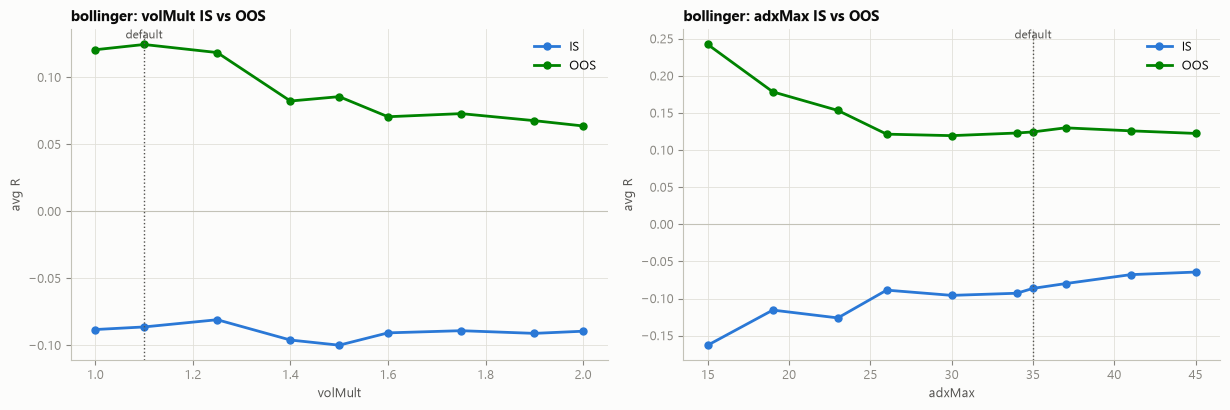

In [4]:
fig, axes = plt.subplots(1, len(PARAMS), figsize=(6.2*len(PARAMS), 4.2), squeeze=False)
for ax, p in zip(axes.flat, PARAMS):
    d = df[df.param == p]
    viz.sweep_lines(d['value'].tolist(), d['is_avgR'].tolist(),
        d['oos_avgR'].tolist(), p, default=defaults.get(p),
        title=f'{STRATEGY}: {p} IS vs OOS', ax=ax)
plt.tight_layout(); plt.show()

## 2 -- Forward-walk progressive tuning

Expanding-window folds. Each fold tunes on the past, tests on the next
unseen block. Watch two things: the **pooled OOS** stat, and whether the
per-fold winner is *stable* (same value each fold) or a coin flip.

In [5]:
pooled, fold_log = walk_forward(CFG, bars_map, spy_bars, STRATEGY, PARAMS,
        MIN_SCORE, COST_BPS, FOLDS, min_trades=15, max_values=9)
flog = pd.DataFrame([{ 'fold': f['fold'], 'chosen': f['chosen'],
        'train_avgR': (f['train'] or {}).get('avg_r', np.nan),
        'test_avgR': (f['test'] or {}).get('avg_r', np.nan),
        'test_n': (f['test'] or {}).get('n', 0)} for f in fold_log])
flog


Walk-forward — bollinger | 4 folds | 20 candidates


  fold 1: tuned<2025-12-02  chose adxMax=15                            train[  44   50.0%  +0.021    1.05]  test[  36   41.7%  -0.233    0.47]


  fold 2: tuned<2026-02-20  chose adxMax=41                            train[1734   47.4%  -0.063    0.87]  test[ 966   45.1%  -0.091    0.81]


  fold 3: tuned<2026-05-07  chose adxMax=45                            train[2855   46.5%  -0.069    0.85]  test[ 620   54.2%  +0.166    1.51]

  POOLED OUT-OF-SAMPLE (1622 trades): 1622   48.5%  +0.004    1.01
  ^ this line is the honest answer; whole-history numbers overfit.


,fold,chosen,train_avgR,test_avgR,test_n
0,1,adxMax=15,0.020680,-0.233356,36
1,2,adxMax=41,-0.062549,-0.091277,966
2,3,adxMax=45,-0.069130,0.165896,620


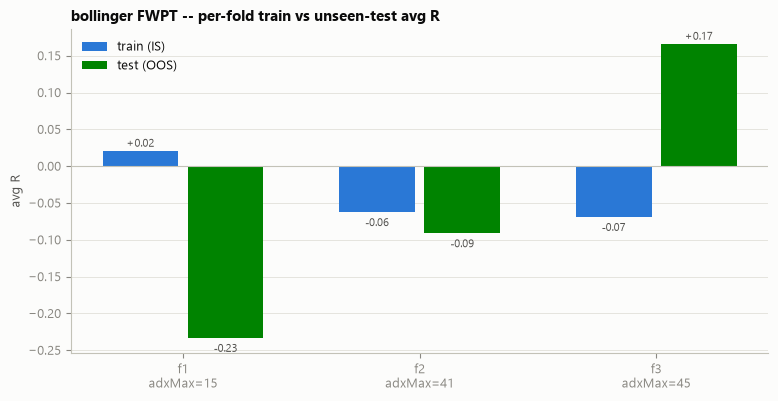

distinct winners across folds: 3 -> UNSTABLE (the best value is noise)


In [6]:
fig, ax = viz.paired_bars(
    [f"f{r.fold}\n{r.chosen[:16]}" for r in flog.itertuples()],
    flog['train_avgR'].tolist(), flog['test_avgR'].tolist(),
    label_a='train (IS)', label_b='test (OOS)', ylabel='avg R',
    title=f'{STRATEGY} FWPT -- per-fold train vs unseen-test avg R')
plt.show()
chosen = set(flog['chosen'])
print(f'distinct winners across folds: {len(chosen)} ->',
      'STABLE' if len(chosen) <= 2 else 'UNSTABLE (the best value is noise)')

## 3 -- Pooled out-of-sample verdict

The single number that decides promotion. Compare to the defaults
baseline (run this notebook with `PARAMS=[]`-equivalent by reading the
`(defaults)` fold rows).

POOLED OOS: n=1622 win=48.5% avgR=+0.004 PF=1.01 t=+0.2


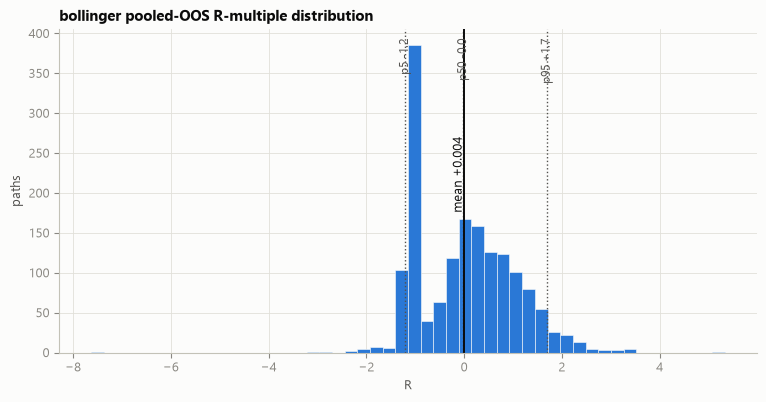

In [7]:
from rhengine.backtest import _stats
st = _stats(pooled)
if st:
    print(f"POOLED OOS: n={st['n']} win={st['win_rate']*100:.1f}% "
          f"avgR={st['avg_r']:+.3f} PF={st['profit_factor']:.2f} t={st['t_stat']:+.1f}")
    viz.dist_hist([t['r_multiple'] for t in pooled], bins=50,
        title=f'{STRATEGY} pooled-OOS R-multiple distribution',
        xlabel='R', x_fmt='{:+.1f}', ref=st['avg_r'], ref_label=f"mean {st['avg_r']:+.3f}")
    plt.show()
else:
    print('no pooled trades')

---
**Promotion bar:** pooled OOS avg R beats the defaults baseline, the
per-fold winner is stable, and t-stat >= 2. Anything that wins IS but
not pooled-OOS stays off. Encode the winner in `strategies.json`
(default/min/max/step) and `config.json`, then re-run the ablation and
Monte Carlo labs.